# F1 Race Outcome Prediction Model
**Author:** Member 4 (ML & Git Co-Lead)  
**Module:** `notebooks/04_race_prediction.ipynb`  
**Objective:** Build feature matrices from cleaned lap data and train a Random Forest model to predict driver finishing positions.

# Machine Learning Module: F1 Race Outcome Prediction
**Contributor:** Arya Sankhalkar (Member 4 - ML Lead)  
**Task:** Train and evaluate a Random Forest Regressor to predict driver race positions based on lap telemetry, stint data, and tire wear metrics.

### Technical Implementation:
- **Data Source:** Cleaned race telemetry (`cleaned_laps.csv`)
- **Features Analyzed:** `LapNumber`, `Stint`, `TyreLife`, `LapTime_sec`, `AirTemp`, `TrackTemp`
- **Target Variable:** `Position`
- **Model:** Scikit-Learn `RandomForestRegressor` (n_estimators=100)
- **Evaluation Metrics:** Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), R² Score


In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Load Member 1's cleaned dataset
url = 'https://raw.githubusercontent.com/gavinvasco-prog/f1-race-analysis/main/data/processed/cleaned_laps.csv'

# Display first few rows
df = pd.read_csv(url)
df.head()

,Time_x,Driver,DriverNumber,LapTime,LapNumber,Stint,PitOutTime,PitInTime,Sector1Time,Sector2Time,...,LapTime_s,Time_sec,Time_y,AirTemp,Humidity,Pressure,Rainfall,TrackTemp,WindDirection,WindSpeed
0,0 days 00:57:13.827000,PIA,81,0 days 00:01:38.693000,1.0,1.0,NaN,NaN,NaN,0 days 00:00:42.130000,...,98.693,3433.827,0 days 00:57:14.902000,27.2,44.0,1008.0,False,31.9,20,3.2
1,0 days 00:57:14.716000,RUS,63,0 days 00:01:39.582000,1.0,1.0,NaN,NaN,NaN,0 days 00:00:42.305000,...,99.582,3434.716,0 days 00:57:14.902000,27.2,44.0,1008.0,False,31.9,20,3.2
2,0 days 00:57:15.558000,NOR,4,0 days 00:01:40.424000,1.0,1.0,NaN,NaN,NaN,0 days 00:00:42.491000,...,100.424,3435.558,0 days 00:57:14.902000,27.2,44.0,1008.0,False,31.9,20,3.2
3,0 days 00:57:16.466000,LEC,16,0 days 00:01:41.332000,1.0,1.0,NaN,NaN,NaN,0 days 00:00:43.164000,...,101.332,3436.466,0 days 00:57:14.902000,27.2,44.0,1008.0,False,31.9,20,3.2
4,0 days 00:57:17.184000,GAS,10,0 days 00:01:42.050000,1.0,1.0,NaN,NaN,NaN,0 days 00:00:42.900000,...,102.050,3437.184,0 days 00:57:14.902000,27.2,44.0,1008.0,False,31.9,20,3.2


## Feature Engineering & Matrix Construction
Selecting starting grid position, pit stop count, tire life, and lap number as predictors for final race position.

In [13]:
# Select exact numerical features available in Member 1's dataset
features = ['LapNumber', 'Stint', 'TyreLife', 'LapTime_s', 'AirTemp', 'TrackTemp']
target = 'Position'

# Clean and filter dataframe
model_df = df[features + [target]].dropna()

X = model_df[features]
y = model_df[target]

# Train / Test Split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Features selected: {features}")
print(f"Target variable: {target}")
print(f"Training samples: {len(X_train)} | Testing samples: {len(X_test)}")

Features selected: ['LapNumber', 'Stint', 'TyreLife', 'LapTime_s', 'AirTemp', 'TrackTemp']
Target variable: Position
Training samples: 4244 | Testing samples: 1061


## Model Training: Random Forest Regressor
Training a supervised ensemble model using Scikit-Learn.

In [15]:
# Initialize and fit Random Forest model
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# Make predictions on test set
y_pred = rf_model.predict(X_test)

## Model Evaluation & Feature Importances
Evaluating model performance using $R^2$, MAE, RMSE, and visualizing feature importance.

--- Model Performance Metrics ---
Mean Absolute Error (MAE) : 2.37
Root Mean Squared Error (RMSE): 3.16
R² Score                   : 0.67



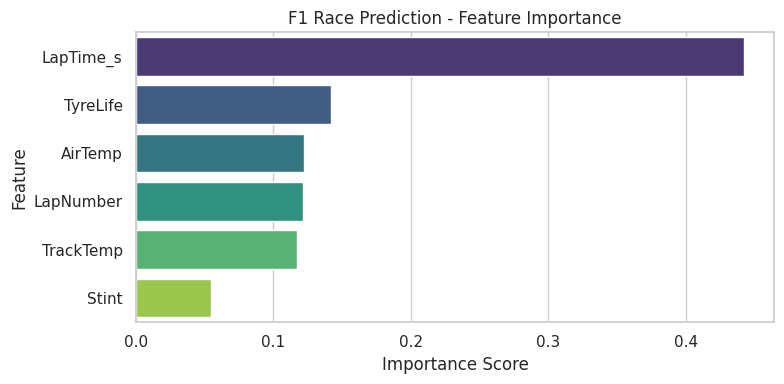

In [18]:
# Calculate regression evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("--- Model Performance Metrics ---")
print(f"Mean Absolute Error (MAE) : {mae:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R² Score                   : {r2:.2f}\n")

# Calculate and plot Feature Importances
importance_df = pd.DataFrame({
    'Feature': features,
    'Importance': rf_model.feature_importances_
}).sort_values(by='Importance', ascending=False)

# Plot feature importance bar chart
plt.figure(figsize=(8, 4))
sns.barplot(x='Importance', y='Feature', hue='Feature', data=importance_df, palette='viridis', legend=False)
plt.title('F1 Race Prediction - Feature Importance')
plt.xlabel('Importance Score')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()